In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt 
from matplotlib.pyplot import figure
import numpy as np 
from PIL import ImageFilter
import os
import math
from tqdm import tqdm
import glob
from pathlib import Path

from __future__ import print_function, division
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
from pathlib import Path
import torchvision.transforms as T
from matplotlib.pyplot import figure

# Ignore warnings
#import warnings
#warnings.filterwarnings("ignore")

### Paths to dataset folders

In [ ]:
root_dir = "/content/drive/MyDrive/Colab Notebooks/semantic_labelling/Dataset/Vaihingen_processed"
train_path = os.path.join(root_dir , 'train')
val_path = os.path.join(root_dir , 'validation')

In [ ]:
#train_imgs = sorted(glob.glob(os.path.join(train_dir,'imgs/*.npy')))

## Dataset

In [ ]:
import numpy as np
import torch
import torch.utils.data as data
import glob
# import tifffile as tiff
# from torchvision import transforms as T

def is_image_file(filename): 
    return any(filename.endswith(extension) for extension in [".tif", '.png', '.jpg', '.npy'])


class train_dataset(data.Dataset):
    def __init__(self, data_path='', size_w=256, size_h=256, flip=0, 
                batch_size=1, transform = None):
        super(train_dataset, self).__init__()
        self.src_list = np.array(sorted(glob.glob(os.path.join(data_path,'imgs/*.npy'))))
        self.lab_list = np.array(sorted(glob.glob(os.path.join(data_path,'masks/*.npy'))))
        self.data_path = data_path
        self.size_w = size_w
        self.size_h = size_h
        self.flip = flip
        self.index = 0
        self.batch_size = batch_size
        self.transform = transform

    def data_iter_index(self, index=1000):
        batch_index = np.random.choice(len(self.src_list), index)
        x_batch = self.src_list[batch_index]
        y_batch = self.lab_list[batch_index]
        data_series = []
        label_series = []

        try:
            for i in range(index):

                # im = tiff.imread(x_batch[i]) / 255.0
                # data_series.append(im[:256, :256, :])
                # mask = tiff.imread(y_batch[i])[:256, :256, :].argmax(axis = -1)
                # label_series.append(mask)
                
                im = np.load(x_batch[i]).transpose([1,2,0]) #/ 255.0  
                # print(data.shape)

                if self.transform:
                  im = self.transform(im)

                data_series.append(im.numpy())
                label_series.append(np.load(y_batch[i]))
                
                self.index += 1

        except OSError:
            return None, None

        
        data_series = torch.from_numpy(np.array(data_series)).type(torch.FloatTensor)
        # data_series = data_series.type(torch.FloatTensor)
        # data_series = data_series.permute(0, 3, 1, 2)
        label_series = torch.from_numpy(np.array(label_series)).type(torch.FloatTensor)
        torch_data = data.TensorDataset(data_series, label_series)
        data_iter = data.DataLoader(
            dataset=torch_data,  # torch TensorDataset format
            batch_size=self.batch_size,  # mini batch size
            shuffle=True, 
            num_workers=0,
        )

        return data_iter

    def data_iter(self):
        data_series = []
        label_series = []
        try:
            for i in range(len(self.src_list)):

                # im = tiff.imread(self.src_list[i]) / 255.0
                # data_series.append(im[:256, :256, :])
                # mask = tiff.imread(self.lab_list[i])[:256, :256, :].argmax(axis = -1)
                # # label_series.append(rgb_to_1Hlabel(mask).argmax(axis = 0))

                im = np.load(self.src_list[i]).transpose([1,2,0])# / 255.0    
                   
                if self.transform:
                  im = self.transform(im)

                data_series.append(im.numpy())
                label_series.append(np.load(self.lab_list[i]))

                self.index += 1

        except OSError:
            return None, None

        data_series = torch.from_numpy(np.array(data_series)).type(torch.FloatTensor)
        # data_series = data_series.permute(0, 3, 1, 2)
        label_series = torch.from_numpy(np.array(label_series)).type(torch.FloatTensor)
        torch_data = data.TensorDataset(data_series, label_series)
        data_iter = data.DataLoader(
            dataset=torch_data,  # torch TensorDataset format
            batch_size=self.batch_size,  # mini batch size
            shuffle=True, 
            num_workers=0, 
        )

        return data_iter

### dataloaders parameters

In [ ]:
batch_size = 4
size_w , size_h = 256, 256

val_trans = T.Compose([
  T.ToTensor()#,
  #T.Normalize(*exp_config['data']['val']['transforms']['normalization'])
])

### dataset definition

In [ ]:
train_dataset_ = train_dataset(train_path, 
                             size_w, size_h, 
                             flip = 0, 
                             batch_size = batch_size,
                             transform = val_trans)

val_dataset_ = train_dataset(val_path, 
                             size_w, size_h, 
                             flip = 0, 
                             batch_size = 1,        #tenere 1
                             transform = val_trans)

### iterator definitions

In [ ]:
train_iter = train_dataset_.data_iter_index(index=1000)

In [ ]:
initial_image, semantic_image = next(iter(train_iter))
initial_image.shape , semantic_image.shape

(torch.Size([4, 3, 256, 256]), torch.Size([4, 256, 256]))

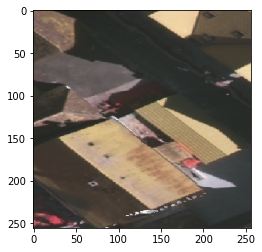

In [ ]:
tensor_top_image_transform = T.ToPILImage()
plt.imshow(tensor_top_image_transform(initial_image[0]))

In [ ]:
semantic_image[0]

tensor([[3., 3., 3.,  ..., 3., 3., 3.],
        [3., 3., 3.,  ..., 3., 3., 3.],
        [3., 3., 3.,  ..., 3., 3., 3.],
        ...,
        [4., 4., 4.,  ..., 3., 3., 3.],
        [4., 4., 4.,  ..., 3., 3., 3.],
        [4., 4., 4.,  ..., 3., 3., 3.]])